# NadiKampus — Topic Detection (BERTopic)

Notebook ini **hanya untuk topic detection** (tanpa klasifikasi dimensi / fine-tuning IndoBERT), jadi jauh lebih ringan.

**Pipeline:** sentence embedding Indonesia → UMAP → HDBSCAN → c-TF-IDF (+ MMR) → **BERTopic**

**Data:** `nadikampus_corpus_model.parquet` (sudah difilter: valid, tanpa duplikat & jawaban kosong). `nadikampus_corpus_all.parquet` hanya dipakai untuk ringkasan pembersihan.
Kolom yang dipakai: `text_clean` (untuk embedding), `text_tokens` (tanpa stopword, untuk kata representasi topik), `timestamp`, `source`, `doc_type`.

**Cara pakai:** jalankan sel dari atas ke bawah. Embedding di-*cache* ke `outputs/`, jadi run ulang jauh lebih cepat.

## 0. Setup
Install sekali di terminal (venv Python 3.10–3.12), lalu jalankan sel cek GPU:

```powershell
pip install torch --index-url https://download.pytorch.org/whl/cu124
pip install pandas pyarrow numpy scikit-learn matplotlib plotly nbformat ipykernel
pip install sentence-transformers bertopic umap-learn hdbscan gensim
```

In [16]:
import sys, torch
print("Python :", sys.version.split()[0])
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))

Python : 3.11.9
PyTorch: 2.14.0+cu126 | CUDA: True
GPU    : NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Konfigurasi

In [17]:
import os, re, json, random, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# ---------------- path ----------------
# folder dicari berurutan; file dicari dengan pola *corpus_model.parquet
DATA_DIRS = [Path("data"), Path("dataoutputprocess"), Path(".")]
OUT_DIR = Path("outputs_teks");  OUT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)

# ---------------- model embedding ----------------
EMB_MODEL    = "firqaaa/indo-sentence-bert-base"
EMB_FALLBACK = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MAX_LEN = 128

# ---------------- topic detection ----------------
MIN_TOKENS_TOPIC  = 3     # dokumen < 3 token tidak ikut membentuk topik (hanya di-assign)
MIN_CLUSTER_SIZE  = 25    # naik -> topik lebih sedikit & umum
OUTLIER_THRESHOLD = 0.35  # similarity minimal untuk memindahkan outlier / dokumen pendek ke topik terdekat
RUN_SWEEP = False         # True -> bandingkan beberapa min_cluster_size

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

def find_file(pattern):
    for d in DATA_DIRS:
        hits = sorted(d.glob(pattern)) if d.exists() else []
        if hits:
            return hits[0]
    raise FileNotFoundError(f"Tidak ada file '{pattern}' di {[str(d.resolve()) for d in DATA_DIRS]}")

device: cuda


## 2. Load data & eksplorasi singkat

In [18]:
df = pd.read_parquet(find_file("*corpus_model.parquet")).reset_index(drop=True)
try:
    df_all = pd.read_parquet(find_file("*corpus_all.parquet"))
except FileNotFoundError:
    df_all = None

for c in ["source", "doc_type"]:
    df[c] = df[c].astype(str)
df["timestamp"] = pd.to_datetime(df["timestamp"])
if "n_tokens" not in df.columns:
    df["n_tokens"] = df["text_tokens"].fillna("").str.split().str.len()
if "n_words" not in df.columns:
    df["n_words"] = df["text_clean"].fillna("").str.split().str.len()
df["text_clean"]  = df["text_clean"].fillna("")
df["text_tokens"] = df["text_tokens"].fillna("")

if df_all is not None:
    print(f"corpus_all  : {len(df_all):,} baris")
print(f"corpus_model: {len(df):,} baris")
print(f"Rentang waktu: {df.timestamp.min()}  ->  {df.timestamp.max()}")
display(df.groupby(["source", "doc_type"]).size().rename("n").to_frame())

corpus_all  : 5,433 baris
corpus_model: 5,342 baris
Rentang waktu: 2026-08-01 03:13:16  ->  2026-10-20 23:20:10


,,n
source,doc_type,
gform,survey_answer,553
telegram,post,4789


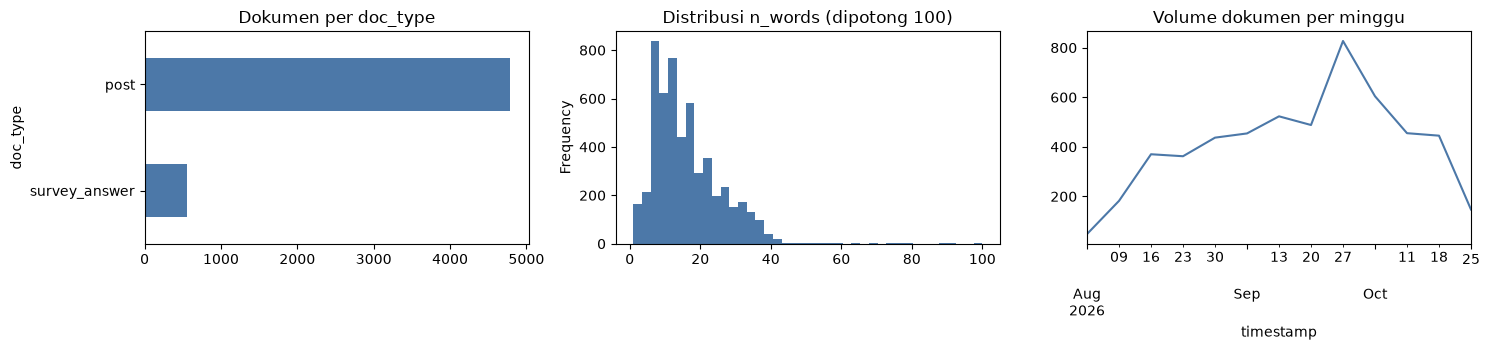

Dokumen dengan n_tokens < MIN_TOKENS_TOPIC: 211


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
df.groupby("doc_type").size().sort_values().plot.barh(ax=ax[0], color="#4C78A8"); ax[0].set_title("Dokumen per doc_type")
df.n_words.clip(upper=100).plot.hist(bins=40, ax=ax[1], color="#4C78A8"); ax[1].set_title("Distribusi n_words (dipotong 100)")
df.set_index("timestamp").resample("W").size().plot(ax=ax[2], color="#4C78A8"); ax[2].set_title("Volume dokumen per minggu")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_overview.png", dpi=150); plt.show()
print("Dokumen dengan n_tokens < MIN_TOKENS_TOPIC:", (df.n_tokens < MIN_TOKENS_TOPIC).sum())

## 3. Sentence embedding
Dihitung sekali dari `text_clean` (teks natural, tidak di-stem) lalu di-cache.

In [20]:
from sentence_transformers import SentenceTransformer

def load_st(name):
    m = SentenceTransformer(name, device=device)
    m.max_seq_length = MAX_LEN
    return m

try:
    st_model, EMB_NAME_USED = load_st(EMB_MODEL), EMB_MODEL
except Exception as e:
    print(f"[!] Gagal memuat {EMB_MODEL}: {type(e).__name__}. Pakai fallback {EMB_FALLBACK}")
    st_model, EMB_NAME_USED = load_st(EMB_FALLBACK), EMB_FALLBACK

emb_path = OUT_DIR / f"emb_{EMB_NAME_USED.replace('/', '_')}_{len(df)}.npy"
if emb_path.exists():
    emb = np.load(emb_path); print("Embedding dimuat dari cache:", emb.shape)
else:
    t0 = time.time()
    emb = st_model.encode(df.text_clean.tolist(), batch_size=64, show_progress_bar=True,
                          normalize_embeddings=True, convert_to_numpy=True)
    np.save(emb_path, emb); print(f"Embedding {emb.shape} selesai dalam {time.time()-t0:.0f} dtk")
assert len(emb) == len(df)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/84 [00:00<?, ?it/s]

Embedding (5342, 768) selesai dalam 8 dtk


## 4. BERTopic
- Embedding dari `text_clean`; **kata representasi topik** dari `text_tokens` (tanpa stopword) agar label bersih.
- Disimpan dua versi: `topic_raw` (apa adanya, outlier = -1) dan `topic` (outlier dipindah ke topik terdekat bila similarity ≥ `OUTLIER_THRESHOLD`).
- Dokumen sangat pendek (< `MIN_TOKENS_TOPIC` token) tidak ikut fit; mereka di-assign ke **centroid topik terdekat** (cosine similarity pada embedding), bukan lewat `transform` HDBSCAN yang cenderung membuang semuanya jadi outlier.

In [21]:
from bertopic import BERTopic
from bertopic.representation import MaximalMarginalRelevance
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

# kata khas menfess yang tidak informatif untuk label topik (tambah sesuai hasil inspeksi)
EXTRA_STOPWORDS = ["sender", "nder", "rek", "ya", "yah", "dong", "sih", "nih", "deh", "kok", "lho", "loh",
                   "aja", "gak", "banget", "tolong", "makasih", "terima", "kasih", "halo", "min", "admin"]

topic_mask = (df.n_tokens >= MIN_TOKENS_TOPIC).to_numpy()
docs_fit = df.loc[topic_mask, "text_tokens"].tolist()
emb_fit  = emb[topic_mask]
print(f"Dokumen untuk fit topik: {topic_mask.sum():,} | hanya di-assign: {(~topic_mask).sum():,}")

def make_topic_model(min_cluster_size=MIN_CLUSTER_SIZE, verbose=True):
    return BERTopic(
        embedding_model=None,   # embedding diberikan manual
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
        hdbscan_model=HDBSCAN(min_cluster_size=min_cluster_size, min_samples=5, metric="euclidean",
                              cluster_selection_method="eom", prediction_data=True),
        vectorizer_model=CountVectorizer(ngram_range=(1, 2), min_df=3, stop_words=EXTRA_STOPWORDS),
        representation_model=MaximalMarginalRelevance(diversity=0.4),
        top_n_words=10, calculate_probabilities=False, verbose=verbose,
    )

Dokumen untuk fit topik: 5,131 | hanya di-assign: 211


In [22]:
topic_model = make_topic_model()
topics, probs = topic_model.fit_transform(docs_fit, embeddings=emb_fit)
topics = np.array(topics)
n_topics = len(set(topics)) - (1 if -1 in topics else 0)
print(f"\nTopik ditemukan: {n_topics} | outlier mentah: {(topics == -1).mean():.1%}")

# pindahkan outlier ke topik terdekat (berdasarkan embedding)
topics_red = topic_model.reduce_outliers(docs_fit, topics.tolist(), strategy="embeddings",
                                         embeddings=emb_fit, threshold=OUTLIER_THRESHOLD)
topic_model.update_topics(docs_fit, topics=topics_red,
                          vectorizer_model=topic_model.vectorizer_model,
                          representation_model=MaximalMarginalRelevance(diversity=0.4))
topics_red = np.array(topics_red)
print(f"Outlier setelah reduce_outliers: {(topics_red == -1).mean():.1%}")

# --- centroid tiap topik (dari embedding dokumen anggota) ---
topic_ids = sorted(t for t in set(topics_red) if t != -1)
centroids = np.vstack([emb_fit[topics_red == t].mean(0) for t in topic_ids])
centroids /= np.linalg.norm(centroids, axis=1, keepdims=True)

def assign_by_centroid(e, thr=OUTLIER_THRESHOLD):
    """Assign embedding ke topik terdekat; -1 bila similarity < thr."""
    sims = e @ centroids.T
    best, mx = sims.argmax(1), sims.max(1)
    return np.where(mx >= thr, np.array(topic_ids)[best], -1), mx

# --- tulis hasil ke dataframe ---
df["topic_raw"] = -1
df["topic"] = -1
df["topic_score"] = np.nan     # dokumen fit: membership prob HDBSCAN | dokumen pendek: cosine ke centroid
df.loc[topic_mask, "topic_raw"]   = topics
df.loc[topic_mask, "topic"]       = topics_red
df.loc[topic_mask, "topic_score"] = np.asarray(probs, dtype=float)

short = ~topic_mask
if short.any():
    t_short, s_short = assign_by_centroid(emb[short])
    df.loc[short, "topic_raw"] = t_short
    df.loc[short, "topic"] = t_short
    df.loc[short, "topic_score"] = s_short

info = topic_model.get_topic_info()
print(f"Outlier akhir di seluruh korpus: {(df.topic == -1).mean():.1%}")
display(info[["Topic", "Count", "Name"]].head(30))

2026-10-26 10:55:39,412 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-26 10:55:45,726 - BERTopic - Dimensionality - Completed ✓
2026-10-26 10:55:45,730 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-26 10:55:45,841 - BERTopic - Cluster - Completed ✓
2026-10-26 10:55:45,848 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-26 10:55:45,959 - BERTopic - Representation - Completed ✓
2026-10-26 10:55:46,099 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.



Topik ditemukan: 38 | outlier mentah: 20.4%
Outlier setelah reduce_outliers: 1.1%
Outlier akhir di seluruh korpus: 1.9%


,Topic,Count,Name
0,-1,57,-1_indonesia_ibu_pergi_suara
1,0,511,0_laptop_jual_hp_beli
2,1,455,1_orang_lgbt_salah_cowok
3,2,306,2_print_komunitas_penscomp_kampus
4,3,287,3_kantin_makan_makanan_foodlab
5,4,289,4_iki_wes_yo_seng
6,5,278,5_motor_kunci_ktm_menemukan
7,6,169,6_dosen_tugas_materi_praktikum
8,7,140,7_kos_info_daerah_gebang
9,8,169,8_lucu_punya_anak_elka


### Inspeksi topik
Baca kata kunci **dan contoh teks asli**, lalu beri nama manusiawi lewat `TOPIC_LABELS` di sel berikutnya.

In [23]:
def show_topic_examples(topic_ids_to_show=None, n_topics=15, n_examples=4):
    ids = topic_ids_to_show or [t for t in info.Topic.tolist() if t != -1][:n_topics]
    for t in ids:
        words = ", ".join(w for w, _ in topic_model.get_topic(t)[:8])
        cnt = int(info.loc[info.Topic == t, "Count"].iloc[0])
        print(f"\n=== Topik {t}  (n={cnt})  :: {words}")
        ex = df[(df.topic == t) & df.topic_score.notna()].nlargest(n_examples, "topic_score")
        for txt in ex.text_clean:
            print("   •", txt[:160].replace("\n", " "))

show_topic_examples()                  # 15 topik terbesar
# show_topic_examples(list(range(15, 40)))   # lihat topik lain


=== Topik 0  (n=511)  :: laptop, jual, hp, beli, budget, info, murah, harga
   • Ada yang jual sepatu futsal gak?
   • Budget sender dari DTME buat laptop mepet banget, max 5jt 🥀 Mau ngegacha, katanya ThinkPad, ASUS EliteBook, Dell Latitude/XPS oke. Enaknya beli online/offline? 
   • saran laptop buat maba telkom dong der budget under 10 plcc bingung
   • Laptop sender gak mau idup 🥹, semalem sender abis tekan update & shutdown terus udah deh, eh barusan sender tekan tombol power ga idup lgi, dicoba cas indikator

=== Topik 1  (n=455)  :: orang, lgbt, salah, cowok, teman, suka, jangan, sendiri
   • heh tolong ya kalau disapa itu balik nyapa dongg, malu bgt udah nyapa tp ga dibales akk (kek ga saling kenal aja) 💔💔
   • Ini kalau lapor ke poster yg dipajang itu apakah yg melapor mendapatkan perlindungan? dan oknum tersebut akan di tindak? dan apakah posisi nya membela oknum? ta
   • Gimana ya cara ngebedain orang yang cuma manfaatin doang sama orang yang memang menghargai perasaan kita


In [24]:
# Isi setelah membaca contoh di atas, mis. {0: "Jual-beli laptop/HP", 2: "Kantin & makanan", ...}
TOPIC_LABELS = {}

name_map = dict(zip(info.Topic, info.Name))
df["topic_label"] = df.topic.map(lambda t: TOPIC_LABELS.get(t, name_map.get(t, str(t))))
print(df.topic_label.value_counts().head(15))

topic_label
0_laptop_jual_hp_beli                515
1_orang_lgbt_salah_cowok             461
2_print_komunitas_penscomp_kampus    318
4_iki_wes_yo_seng                    293
3_kantin_makan_makanan_foodlab       291
5_motor_kunci_ktm_menemukan          278
8_lucu_punya_anak_elka               177
6_dosen_tugas_materi_praktikum       171
11_ukm_ikut_komunitas_join           167
18_kuliah_semester_prodi_maba        161
7_kos_info_daerah_gebang             140
12_jam_baak_buka_tanggal             136
20_foto_ig_tanya_akun                128
14_menonton_novel_film_video         121
17_uts_semester_kelas_nilai          119
Name: count, dtype: int64


### Visualisasi (disimpan sebagai HTML interaktif di `outputs/figures/`)

In [25]:
def show_and_save(make_fig, fname):
    try:
        fig = make_fig()
        fig.write_html(str(FIG_DIR / fname)); fig.show()
    except Exception as e:
        print(f"[skip {fname}] {type(e).__name__}: {e}")

n_real = len([t for t in info.Topic if t != -1])
show_and_save(lambda: topic_model.visualize_barchart(top_n_topics=min(12, n_real), n_words=8), "topic_barchart.html")
show_and_save(lambda: topic_model.visualize_topics(), "topic_intertopic_map.html")
show_and_save(lambda: topic_model.visualize_hierarchy(), "topic_hierarchy.html")
show_and_save(lambda: topic_model.visualize_heatmap(), "topic_similarity_heatmap.html")

In [26]:
# Tren topik dari waktu ke waktu
ts_fit = df.loc[topic_mask, "timestamp"].tolist()
topics_over_time = topic_model.topics_over_time(docs_fit, ts_fit, nr_bins=10)
show_and_save(lambda: topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=min(8, n_real)),
              "topic_over_time.html")

10it [00:00, 36.20it/s]


### Evaluasi kualitas topik
- **Coherence c_v** (makin tinggi makin koheren) dan **topic diversity** (proporsi kata unik antar topik).
- **Validasi eksternal lemah** (opsional, jika kolom `dimension` ada): kesesuaian topik dengan label dimensi pada jawaban survei (NMI/ARI). Tidak diharapkan tinggi, berguna untuk membandingkan konfigurasi.

In [27]:
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel

def topic_quality(tm, docs, topk=10):
    tokenized = [d.split() for d in docs]
    dictionary = Dictionary(tokenized)
    tw = []
    for t in tm.get_topics():
        if t == -1: continue
        words = [w for w, _ in tm.get_topic(t)[:topk]]
        uni = list(dict.fromkeys(x for w in words for x in w.split() if x in dictionary.token2id))  # pecah bigram
        if len(uni) >= 2: tw.append(uni)
    coh = CoherenceModel(topics=tw, texts=tokenized, dictionary=dictionary, coherence="c_v", processes=1).get_coherence()
    flat = [w for ws in tw for w in ws]
    return {"n_topics": len(tw), "coherence_c_v": round(coh, 4), "diversity": round(len(set(flat)) / len(flat), 4)}

print("Kualitas topik:", topic_quality(topic_model, docs_fit))

if "dimension" in df.columns:
    from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
    g = df[(df.source == "gform") & df.dimension.notna() & (df.topic != -1)]
    if len(g):
        print(f"Kesesuaian dengan label dimension (gform, n={len(g)}): "
              f"NMI={normalized_mutual_info_score(g.dimension.astype(str), g.topic):.3f} | "
              f"ARI={adjusted_rand_score(g.dimension.astype(str), g.topic):.3f}")

Kualitas topik: {'n_topics': 38, 'coherence_c_v': np.float64(0.4426), 'diversity': 0.7836}
Kesesuaian dengan label dimension (gform, n=508): NMI=0.382 | ARI=0.355


In [28]:
if RUN_SWEEP:
    rows = []
    for mcs in [15, 25, 40, 60]:
        tm = make_topic_model(mcs, verbose=False)
        tp, _ = tm.fit_transform(docs_fit, embeddings=emb_fit)
        q = topic_quality(tm, docs_fit); q.update({"min_cluster_size": mcs, "outlier_%": round((np.array(tp) == -1).mean() * 100, 1)})
        rows.append(q); print(q)
    display(pd.DataFrame(rows).set_index("min_cluster_size"))
else:
    print("RUN_SWEEP=False -> lewati. Set True di sel konfigurasi untuk membandingkan min_cluster_size.")

RUN_SWEEP=False -> lewati. Set True di sel konfigurasi untuk membandingkan min_cluster_size.


## 5. Simpan hasil

In [29]:
# --- model ---
try:
    topic_model.save(str(OUT_DIR / "bertopic_model"), serialization="safetensors",
                     save_ctfidf=True, save_embedding_model=EMB_NAME_USED)
except Exception as e:
    print(f"[skip save model] {type(e).__name__}: {e}")

# --- ringkasan topik + contoh dokumen representatif ---
info = topic_model.get_topic_info()
info["label"] = info.Topic.map(lambda t: TOPIC_LABELS.get(t, ""))
info.to_csv(OUT_DIR / "topic_info.csv", index=False, encoding="utf-8-sig")

rep = (df[df.topic != -1].sort_values("topic_score", ascending=False)
         .groupby("topic").head(5)[["topic", "topic_label", "source", "doc_type", "topic_score", "text_clean"]]
         .sort_values(["topic", "topic_score"], ascending=[True, False]))
rep.to_csv(OUT_DIR / "topic_representative_docs.csv", index=False, encoding="utf-8-sig")

# --- tren topik bulanan (siap untuk dashboard) ---
trend = (df[df.topic != -1].assign(bulan=lambda d: d.timestamp.dt.to_period("M").astype(str))
           .groupby(["bulan", "topic", "topic_label"]).size().rename("n").reset_index())
trend.to_csv(OUT_DIR / "topic_monthly_trend.csv", index=False, encoding="utf-8-sig")

# --- hasil per dokumen ---
out_cols = [c for c in ["doc_id", "source", "doc_type", "timestamp", "text_clean",
                        "topic_raw", "topic", "topic_label", "topic_score"] if c in df.columns]
df[out_cols].to_parquet(OUT_DIR / "nadikampus_topics.parquet", index=False)
df[out_cols].to_csv(OUT_DIR / "nadikampus_topics.csv", index=False, encoding="utf-8-sig")
print("Tersimpan di outputs/: bertopic_model, topic_info.csv, topic_representative_docs.csv, "
      "topic_monthly_trend.csv, nadikampus_topics.(parquet|csv)")

Tersimpan di outputs/: bertopic_model, topic_info.csv, topic_representative_docs.csv, topic_monthly_trend.csv, nadikampus_topics.(parquet|csv)


## 6. Inferensi untuk teks baru

In [30]:
def analyze(texts, thr=OUTLIER_THRESHOLD):
    """Topik terdekat (by centroid) untuk teks baru. Contoh: analyze(["UKT mahal banget"])"""
    texts = [texts] if isinstance(texts, str) else list(texts)
    e = st_model.encode(texts, normalize_embeddings=True, convert_to_numpy=True)
    t, s = assign_by_centroid(e, thr)
    return pd.DataFrame({
        "text": texts, "topic": t, "similarity": s.round(3),
        "topic_label": [df.loc[df.topic == x, "topic_label"].iloc[0] if x != -1 else "-" for x in t],
        "topic_words": [", ".join(w for w, _ in topic_model.get_topic(x)[:5]) if x != -1 else "-" for x in t]})

analyze(["Ada yang jual laptop second harga murah?",
         "Kantin hari ini buka jam berapa ya",
         "Motor saya hilang di parkiran"])

,text,topic,similarity,topic_label,topic_words
0,Ada yang jual laptop second harga murah?,0,0.689,0_laptop_jual_hp_beli,"laptop, jual, hp, beli, budget"
1,Kantin hari ini buka jam berapa ya,3,0.613,3_kantin_makan_makanan_foodlab,"kantin, makan, makanan, foodlab, ayam"
2,Motor saya hilang di parkiran,5,0.610,5_motor_kunci_ktm_menemukan,"motor, kunci, ktm, menemukan, parkir"


## Catatan
- **Topik terlalu banyak/sedikit:** ubah `MIN_CLUSTER_SIZE` (atau `RUN_SWEEP=True`). Topik campur-aduk bahasa Jawa (mis. `iki, wes, yo`) bisa ditangani dengan menambah kata ke `EXTRA_STOPWORDS`.
- **Banyak outlier:** turunkan `OUTLIER_THRESHOLD` (mis. 0.30) atau `MIN_CLUSTER_SIZE`.
- **Dokumen pendek** (< `MIN_TOKENS_TOPIC` token) di-assign lewat centroid; bila ingin diabaikan seluruhnya, filter `n_tokens >= MIN_TOKENS_TOPIC` saat analisis.
- Hasil reproducible (seed 42, UMAP `random_state`) pada mesin yang sama.